In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

In [3]:
# Preprocessing
transform = transforms.Compose([
    transforms.Pad(2),        # Pad 28x28 images to 32x32
    transforms.ToTensor(),    # Convert images to tensors

])

batch_size = 128


In [4]:
# load data
train_dataset = datasets.FashionMNIST(
    root="./data", train=True, transform=transform, download=True
)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = datasets.FashionMNIST(
    root="./data", train=False, transform=transform, download=True
)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 26.4M/26.4M [00:08<00:00, 3.07MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 1.22MB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.66MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.6MB/s]


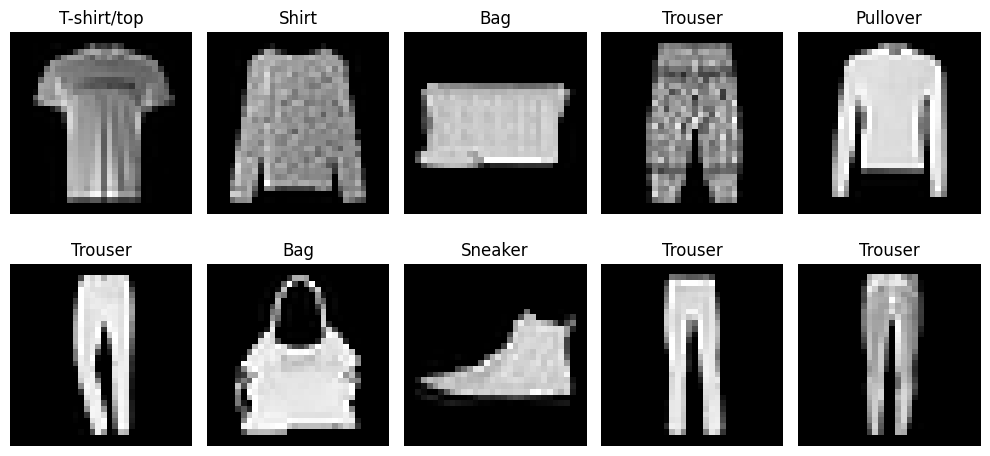

In [21]:
class_labels = {
 0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

def plot_sample_images(loader):
    data_iter = iter(loader)
    images, labels = next(data_iter)
    images = images.numpy()

    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(class_labels[labels[i].item()])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(train_loader)

### How does reducing the dimensionality help the model?
Réduction de dimension: force le modèle à compresser l’info, donc à extraire les motifs importants et ignorer du bruit.

### What happens if the latent space is too small or too large?
Latent trop petit: perte d’info, reconstructions floues, détails manquants.

Latent trop grand: copie quasi directe, embeddings moins structurés, généralisation plus faible.


In [6]:
class Autoencoder(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        super(Autoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        flattened_size, decode_shape = self.calculate_flattened_size(self.encoder, input_shape)

        # Latent space (flatten + linear)
        self.fc = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flattened_size),
            nn.Unflatten(1, decode_shape[1:]),

            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()  # valeurs entre 0 et 1
        )

    def calculate_flattened_size(self, model, input_shape):
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
            return output.numel(), output.shape

    def forward(self, x):
        x = self.encoder(x)
        latent = self.fc(x)
        x = self.decoder(latent)
        return x, latent


# Test dimension consistency
x_sample = torch.randn(1, 1, 32, 32)
model_test = Autoencoder()
image_test, latent_space = model_test(x_sample)
assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"
print("OK: dimensions cohérentes")

OK: dimensions cohérentes


Start Training...


Evaluating: 100%|██████████| 79/79 [00:02<00:00, 34.63it/s]


Epoch [1/10] | Train MSE: 0.069472 | Val MSE: 0.039574 | Val BCE: 0.311031


Evaluating: 100%|██████████| 79/79 [00:02<00:00, 33.34it/s]


Epoch [2/10] | Train MSE: 0.034988 | Val MSE: 0.032489 | Val BCE: 0.295159


...

Epoch [8/10] | Train MSE: 0.028263 | Val MSE: 0.027904 | Val BCE: 0.279338


Evaluating: 100%|██████████| 79/79 [00:02<00:00, 33.69it/s]


Epoch [9/10] | Train MSE: 0.027857 | Val MSE: 0.027543 | Val BCE: 0.277371


Evaluating: 100%|██████████| 79/79 [00:02<00:00, 32.33it/s]


Epoch [10/10] | Train MSE: 0.027551 | Val MSE: 0.027231 | Val BCE: 0.275651


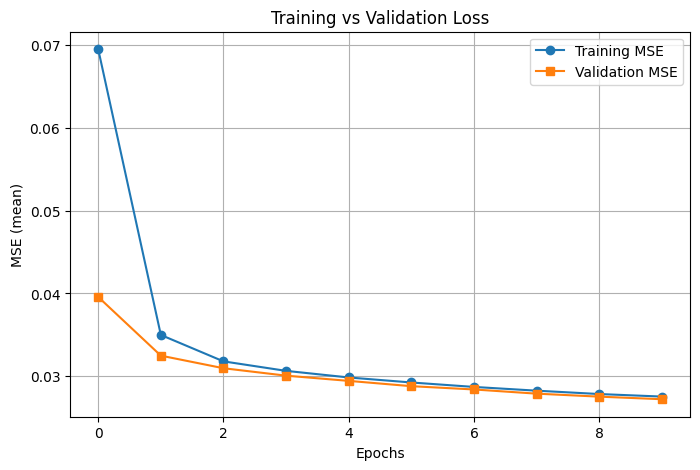

In [31]:
from tqdm import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def evaluate_model(model, loader):
    model.eval()
    total_mse = 0.0
    total_bce = 0.0

    # Moyennes par élément (pixel) pour être comparable avec le train
    mse_fn = nn.MSELoss(reduction="mean")
    bce_fn = nn.BCELoss(reduction="mean")

    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)
            recon_x, _ = model(x)

            mse = mse_fn(recon_x, x)
            bce = bce_fn(recon_x, x)

            # Pondération par taille batch pour moyenne finale dataset
            total_mse += mse.item() * x.size(0)
            total_bce += bce.item() * x.size(0)

    avg_mse = total_mse / len(loader.dataset)
    avg_bce = total_bce / len(loader.dataset)
    return avg_mse, avg_bce


def plot_training_loss(train_losses, val_losses):
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training MSE", marker="o")
    plt.plot(val_losses, label="Validation MSE", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("MSE (mean)")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()


def train_model(model, train_loader, val_loader, epochs):
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    # MSE moyenne (même échelle que la validation)
    loss_fn_train = nn.MSELoss(reduction="mean")

    print("Start Training...")
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        total_train = 0.0

        tqdm_loader = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        for x, _ in tqdm_loader:
            x = x.to(device)
            recon_x, _ = model(x)

            loss = loss_fn_train(recon_x, x)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Pondération par taille batch pour moyenne finale dataset
            total_train += loss.item() * x.size(0)
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_train / len(train_loader.dataset)
        avg_val_loss, ce_loss = evaluate_model(model, val_loader)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train MSE: {avg_train_loss:.6f} | "
            f"Val MSE: {avg_val_loss:.6f} | "
            f"Val BCE: {ce_loss:.6f}"
        )

    plot_training_loss(train_losses, val_losses)


autoencoder = Autoencoder(latent_dim=2)
train_model(autoencoder, train_loader, val_loader, epochs=10)

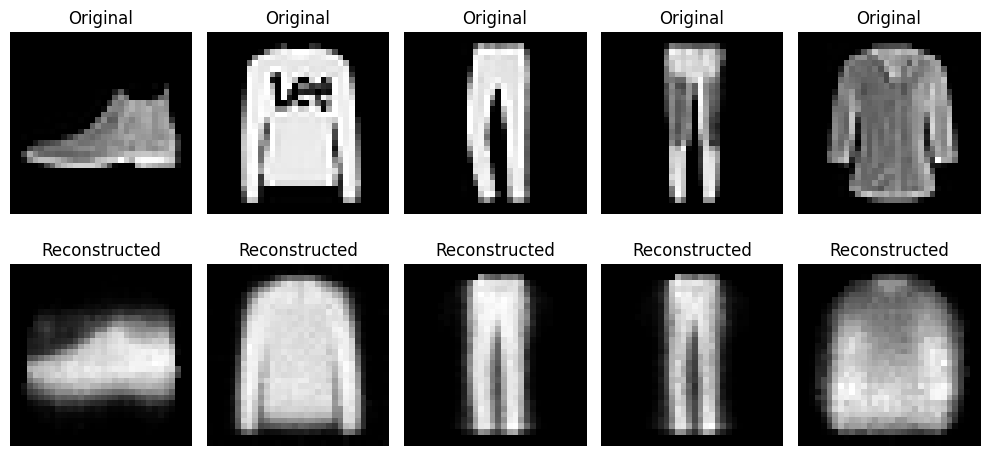

In [32]:
def plot_reconstructions(model, loader, ex=True):
    model.eval()
    model_cpu = model.to("cpu")

    with torch.no_grad():
        if ex:
            for x, _ in loader:
                recon_x, _ = model_cpu(x)
                break
        else:
            x = loader
            recon_x = model_cpu.decoder(x)

        x_np = x.cpu().numpy()
        recon_np = recon_x.cpu().numpy()

        plt.figure(figsize=(10, 5))
        for i in range(5):
            if ex:
                plt.subplot(2, 5, i + 1)
                plt.imshow(x_np[i].squeeze(), cmap="gray")
                plt.title("Original")
                plt.axis("off")

            plt.subplot(2, 5, i + 6)
            plt.imshow(recon_np[i].squeeze(), cmap="gray")
            plt.title("Reconstructed")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

plot_reconstructions(autoencoder, val_loader)

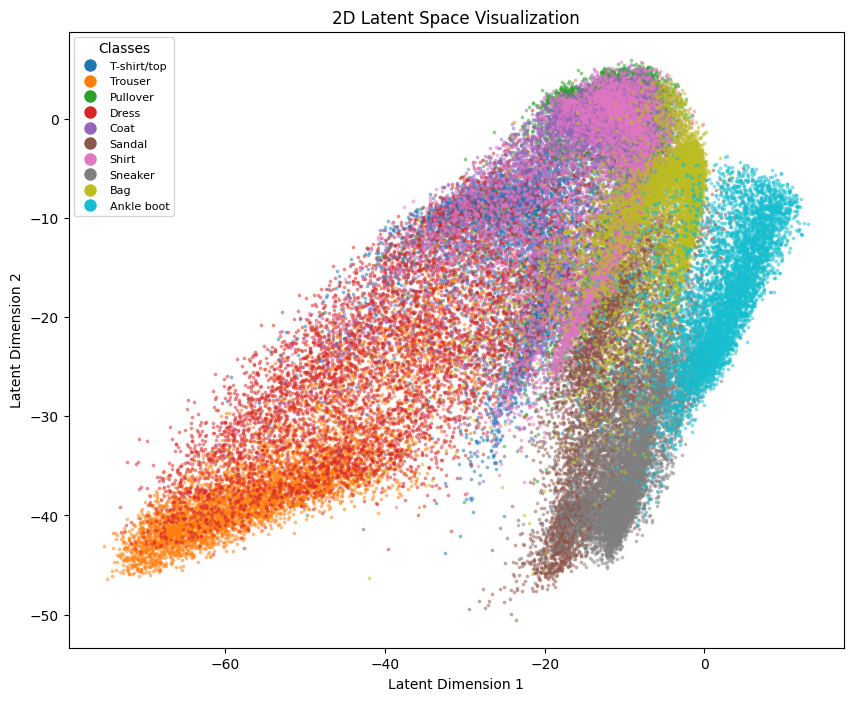

In [33]:
embeddings = []
labels = []

autoencoder = autoencoder.to(device)

with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        _, latent = autoencoder(x)
        embeddings.append(latent.cpu().numpy())
        labels.append(y.numpy())

embeddings = np.concatenate(embeddings, axis=0)
labels = np.concatenate(labels, axis=0)

unique_labels = np.unique(labels)

autoencoder = autoencoder.to("cpu")

colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))
plt.figure(figsize=(10, 8))
legend_handles = []

for i, label in enumerate(unique_labels):
    indices = np.where(labels == label)[0]
    plt.scatter(
        embeddings[indices, 0], embeddings[indices, 1],
        c=[colors[i]], alpha=0.4, s=3, label=class_labels[label]
    )
    legend_handles.append(
        Line2D([0], [0], marker='o', color='w',
               label=class_labels[label],
               markersize=10, markerfacecolor=colors[i])
    )

plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("2D Latent Space Visualization")
plt.legend(handles=legend_handles, title="Classes", loc="upper left", fontsize=8)
plt.show()

Generated Latent Samples (in-distribution):
 tensor([[-15.6976, -10.5255],
        [-35.7936,  -6.0823],
        [-23.4822, -34.6361],
        [-35.5954, -27.5101],
        [ -9.1913,  13.2042]])


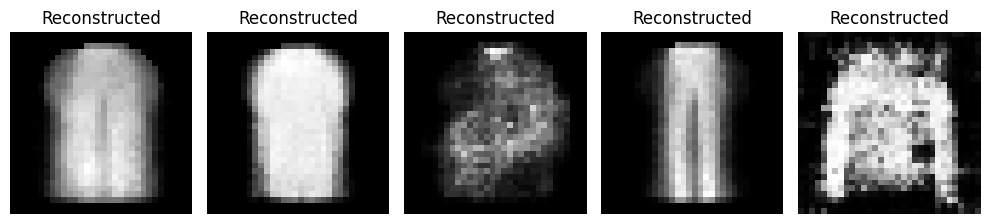

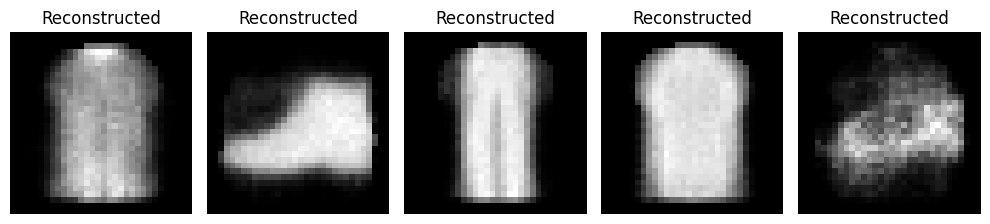

In [34]:
# Échantillonnage latent réaliste: autour de la distribution apprise
latent_mean = np.mean(embeddings, axis=0)
latent_std = np.std(embeddings, axis=0) + 1e-6

sample = torch.tensor(
    np.random.normal(loc=latent_mean, scale=latent_std, size=(5, 2)),
    dtype=torch.float32
)

print("Generated Latent Samples (in-distribution):\n", sample)
plot_reconstructions(autoencoder, sample, ex=False)

# Exemples contrôlés proches du centre latent
manual_samples = np.array([
    latent_mean,
    latent_mean + np.array([latent_std[0], 0.0]),
    latent_mean - np.array([latent_std[0], 0.0]),
    latent_mean + np.array([0.0, latent_std[1]]),
    latent_mean - np.array([0.0, latent_std[1]]),
], dtype=np.float32)

x_sample = torch.tensor(manual_samples, dtype=torch.float32)
plot_reconstructions(autoencoder, x_sample, ex=False)

In [26]:
torch.save(autoencoder.state_dict(), "VAmodel_state_dict.pth")
print("Modèle sauvegardé")

Modèle sauvegardé
